# **Bridge Pledge Score Calculation**

This notebook integrates all preprocessed metrics (Sources A–F, M, N, P) to compute each Member's **Bridge Pledge** score—a composite measure of bipartisan collaboration across sponsorships, communications, district lean, and ideology.  

The final score combines standardized (0–100) values from each source, weighted according to our methodology, along with attendance and caucus‐membership bonuses. This notebook serves as a comprehensive demonstration of the complete Bridge Grades calculation process.

For full methodology, definitions, and source details, see the Bridge Grades framework on our website: https://bridgegrades.org/methodology

- **Last Update:** February 16, 2026  


## **Configuration & File Existence Checks**

In this section we verify that all input files exist before proceeding, and validate that our `weights` dictionary matches the set of loaded source labels.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Global parameters
att_pct   = 0.2   # Minimum attendance proportion
weights   = {
    'A': 3,   # Source A: num_bills_with_cross_party_cosponsors
    'B': 2,   # Source B: num_cross_party_cosponsored_bills
    'C': 1,   # Source C: communications that support members of the opposite party
    'D': 1,   # Source D: proportion of communications that support members of the opposite party
    'E': 1,   # Source E: communications classified as personal attacks
    'F': 1,   # Source F: proportion of communications classified as personal attacks
}

bonuses = {
    'pvi_value_cap': 15, # number of PVI points to cap at
    'max_P_bonus_scaling_factor': 0.01, # scaling factor for P bonus
    'max_N_bonus_scaling_factor': 0.05, # scaling factor for N bonus
    'max_M_bonus_scaling_factor': 0.38 # scaling factor for M bonus
}

# Define all required file paths
BASE_DIR = '/content/drive/Shareddrives/Data Archive/Bridge_Grades/Output_Files/Temp_Files'
BASE_DIR_II = '/content/drive/Shareddrives/Data Archive/Bridge_Grades/Input_Files/Snapshot_Raw_2026_06_02/Raw_Others_2026_06_02'
paths = {
    'meta':        f"{BASE_DIR_II}/119th_Congress_20260602.csv",
    'A':           f"{BASE_DIR}/Temp_A/Temp_A_v1.4.0_2026_06_02.csv",
    'B':           f"{BASE_DIR}/Temp_B/Temp_B_v1.7.0_2026_06_02.csv",
    'C':           f"{BASE_DIR}/Temp_C/Temp_C_v1.0.1_2026_06_02.csv",
    'D':           f"{BASE_DIR}/Temp_D/Temp_D_v1.0.1_2026_06_02.csv",
    'E':           f"{BASE_DIR}/Temp_E/Temp_E_v1.0.1_2026_06_02.csv",
    'F':           f"{BASE_DIR}/Temp_F/Temp_F_v1.0.1_2026_06_02.csv",
    'M_House':     f"{BASE_DIR}/Temp_M/Temp_M_House_v1.0.0_2026_06_02.csv",
    'M_Senate':    f"{BASE_DIR}/Temp_M/Temp_M_Senate_v1.0.0_2026_06_02.csv",
    'N_House':     f"{BASE_DIR}/Temp_N/Temp_N_House_v1.0.0_2026_06_02.csv",
    'N_Senate':    f"{BASE_DIR}/Temp_N/Temp_N_Senate_v1.0.0_2026_06_02.csv",
    'P':           f"{BASE_DIR}/Temp_P/Temp_P_v1.0.0_2026_06_02",
}

# Load raw APP profiles (attendance data)
source_APP_profiles= pd.read_csv(
    f"{BASE_DIR_II}/profiles.csv",
    usecols=['full_name','bioguide_id','attendance_total','attendance_max']
)

# Check each file exists
missing_files = [key for key, p in paths.items() if not os.path.exists(p)]
if missing_files:
    raise FileNotFoundError(f"Missing input files for sources: {missing_files}")
print("All input files found.")


All input files found.


## **Load DataFrames & Validate Weights**

We load each CSV into a DataFrame and then ensure the set of weight keys matches the loaded source labels exactly.


In [4]:
# Load master metadata
meta_data        = pd.read_csv(paths['meta'])

# Load each source DataFrame
source_A         = pd.read_csv(paths['A'])
source_B         = pd.read_csv(paths['B'])
source_C         = pd.read_csv(paths['C'])
source_D         = pd.read_csv(paths['D'])
source_E         = pd.read_csv(paths['E'])
source_F         = pd.read_csv(paths['F'])
#source_APP       = pd.read_csv(paths['CDEF'])
source_M_House   = pd.read_csv(paths['M_House'])
source_M_Senate  = pd.read_csv(paths['M_Senate'])
source_N_House   = pd.read_csv(paths['N_House'])
source_N_Senate  = pd.read_csv(paths['N_Senate'])
source_P         = pd.read_csv(paths['P'])

# Verify weight keys vs. sources to be scored (A–F)
loaded_sources = set(weights.keys())
expected_sources = {'A','B','C','D','E','F'}
if loaded_sources != expected_sources:
    raise ValueError(
        f"Weights keys {loaded_sources} do not match expected {expected_sources}"
    )

print("Weights validated against source labels.")


Weights validated against source labels.


## **Build Base Member Tables**

In this section we initialize our working DataFrames for the House and Senate by subsetting the master `meta_data`. These tables will be the foundation for merging each source's metrics.


In [5]:
# Preview master metadata
meta_data.head(10)


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,2025,NaN,2026-05-21T15:05:48Z,https://www.congress.gov/img/member/6a0f0dcb69...
1,V000139,Matt Van Epps,Matt,NaN,Van Epps,NaN,House,Tennessee,7.0,Republican,2025,NaN,2026-05-14T15:42:06Z,https://www.congress.gov/img/member/6931b7d5f4...
2,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,2013,NaN,2026-05-05T10:30:39Z,https://www.congress.gov/img/member/b001288_20...
3,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,2024,NaN,2026-04-28T10:32:24Z,https://www.congress.gov/img/member/677d870dfd...
4,A000383,Alan Armstrong,Alan,NaN,Armstrong,NaN,Senate,Oklahoma,NaN,Republican,2026,NaN,2026-04-28T10:30:22Z,No Image Available
5,M001246,Analilia Mejia,Analilia,NaN,Mejia,NaN,House,New Jersey,11.0,Democratic,2026,NaN,2026-04-24T19:47:06Z,https://www.congress.gov/img/member/69eb974327...
6,F000485,Clay Fuller,Clay,NaN,Fuller,NaN,House,Georgia,14.0,Republican,2026,NaN,2026-04-24T19:46:09Z,https://www.congress.gov/img/member/69eb95e527...
7,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,2013,NaN,2026-04-09T20:03:37Z,https://www.congress.gov/img/member/69d7f5b073...
8,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,2025,NaN,2026-04-09T20:03:04Z,https://www.congress.gov/img/member/69d7f4ee73...
9,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,2019,NaN,2026-04-09T20:02:15Z,https://www.congress.gov/img/member/69d7f41673...


In [6]:
# Subset to House members
house_final = meta_data.query("Chamber=='House'").copy()
print(f"House members: {house_final.shape[0]}")
house_final.head()

House members: 436


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,2025,NaN,2026-05-21T15:05:48Z,https://www.congress.gov/img/member/6a0f0dcb69...
1,V000139,Matt Van Epps,Matt,NaN,Van Epps,NaN,House,Tennessee,7.0,Republican,2025,NaN,2026-05-14T15:42:06Z,https://www.congress.gov/img/member/6931b7d5f4...
5,M001246,Analilia Mejia,Analilia,NaN,Mejia,NaN,House,New Jersey,11.0,Democratic,2026,NaN,2026-04-24T19:47:06Z,https://www.congress.gov/img/member/69eb974327...
6,F000485,Clay Fuller,Clay,NaN,Fuller,NaN,House,Georgia,14.0,Republican,2026,NaN,2026-04-24T19:46:09Z,https://www.congress.gov/img/member/69eb95e527...
7,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,2013,NaN,2026-04-09T20:03:37Z,https://www.congress.gov/img/member/69d7f5b073...


In [7]:
# Subset to Senate members
senate_final = meta_data.query("Chamber=='Senate'").copy()
print(f"Senate members: {senate_final.shape[0]}")
senate_final.head()

Senate members: 100


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl
2,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,2013,NaN,2026-05-05T10:30:39Z,https://www.congress.gov/img/member/b001288_20...
3,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,2024,NaN,2026-04-28T10:32:24Z,https://www.congress.gov/img/member/677d870dfd...
4,A000383,Alan Armstrong,Alan,NaN,Armstrong,NaN,Senate,Oklahoma,NaN,Republican,2026,NaN,2026-04-28T10:30:22Z,No Image Available
12,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,2017,NaN,2026-03-08T10:33:08Z,https://www.congress.gov/img/member/y000064_20...
13,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,1996,NaN,2026-03-08T10:33:07Z,https://www.congress.gov/img/member/w000779_20...


## **Attendance Filtering**

Legislators below the minimum attendance threshold (`att_pct`) are excluded from scoring. We calculate each member's attendance percentage and remove those below `att_pct`.


In [8]:
source_APP_profiles

,bioguide_id,full_name,attendance_total,attendance_max
0,C000127,Maria Cantwell,782,784
1,K000367,Amy Klobuchar,775,784
2,S000033,Bernard Sanders,726,784
3,W000802,Sheldon Whitehouse,754,784
4,B001261,John Barrasso,780,784
...,...,...,...,...
531,V000139,Matt Van Epps,213,469
532,M001245,Christian Menefee,114,469
533,A000383,Alan Armstrong,63,784
534,F000485,Clay Fuller,67,469


In [9]:
# Extract attendance data
source_att = source_APP_profiles[[
    'full_name','bioguide_id','attendance_total','attendance_max'
]].copy()
source_att.head()

,full_name,bioguide_id,attendance_total,attendance_max
0,Maria Cantwell,C000127,782,784
1,Amy Klobuchar,K000367,775,784
2,Bernard Sanders,S000033,726,784
3,Sheldon Whitehouse,W000802,754,784
4,John Barrasso,B001261,780,784


In [10]:
house_final_without_att = source_att.merge(house_final, on='bioguide_id', how='right')
house_final_without_att = house_final_without_att[[
    'full_name','bioguide_id','attendance_total','attendance_max'
]]
house_final_without_att = house_final_without_att[house_final_without_att['attendance_total'].isna()]
house_final_without_att

,full_name,bioguide_id,attendance_total,attendance_max


In [11]:
len(house_final_without_att)

0

In [12]:
# Check for missing attendance data
missing_attendance = source_att[source_att['attendance_total'].isna()]
print(f"Legislators with missing attendance data: {len(missing_attendance)}")
print("Note: Missing legislators are typically non-voting members from territories.")
missing_attendance

Legislators with missing attendance data: 0
Note: Missing legislators are typically non-voting members from territories.


,full_name,bioguide_id,attendance_total,attendance_max


In [13]:
# Fill missing totals with zero
source_att['attendance_total'] = source_att['attendance_total'].fillna(0)
source_att['attendance_max'] = source_att['attendance_max'].fillna(0)

source_att['attendance_pct'] = np.where(
    (source_att['attendance_total'] == 0) | (source_att['attendance_max'] == 0),
    0,
    source_att['attendance_total'] / source_att['attendance_max']
)

# Identify members below threshold
low_att = source_att.query("attendance_pct < @att_pct").drop_duplicates(subset='bioguide_id')
low_att = pd.concat([low_att[['full_name','bioguide_id','attendance_pct']], house_final_without_att], ignore_index=True)
print(f"Legislators below {att_pct*100}% attendance threshold: {len(low_att)}")
print("Note: All legislators with low attendance are non-voting members from territories.")
low_att


Legislators below 20.0% attendance threshold: 9
Note: All legislators with low attendance are non-voting members from territories.


,full_name,bioguide_id,attendance_pct,attendance_total,attendance_max
0,Eleanor Norton,N000147,0.104478,NaN,NaN
1,Stacey Plaskett,P000610,0.081023,NaN,NaN
2,Aumua Amata Radewagen,R000600,0.027719,NaN,NaN
3,James (Jim) Moylan,M001219,0.095949,NaN,NaN
4,Kimberlyn King-Hinds,K000404,0.081023,NaN,NaN
5,Pablo José Hernández Rivera,H001103,0.104478,NaN,NaN
6,Alan Armstrong,A000383,0.080357,NaN,NaN
7,Clay Fuller,F000485,0.142857,NaN,NaN
8,Analilia Mejia,M001246,0.113006,NaN,NaN


In [14]:
"""from google.colab import sheets
sheet = sheets.InteractiveSheet(df=source_att)"""

'from google.colab import sheets\nsheet = sheets.InteractiveSheet(df=source_att)'

In [15]:
# Remove low‐attendance members from both tables
to_remove = set(low_att['bioguide_id'])
to_remove = to_remove.union(house_final_without_att['bioguide_id'])
house_final = house_final[~house_final['bioguide_id'].isin(to_remove)].copy()
senate_final = senate_final[~senate_final['bioguide_id'].isin(to_remove)].copy()

print(f"Final House members: {house_final.shape[0]}")
print(f"Final Senate members: {senate_final.shape[0]}")


Final House members: 428
Final Senate members: 99


In [16]:
to_remove

{'A000383',
 'F000485',
 'H001103',
 'K000404',
 'M001219',
 'M001246',
 'N000147',
 'P000610',
 'R000600'}

In [17]:
# Remove low‐attendance members from both tables
to_remove = set(low_att['bioguide_id'])
house_final = house_final[~house_final['bioguide_id'].isin(to_remove)].copy()
senate_final = senate_final[~senate_final['bioguide_id'].isin(to_remove)].copy()

print(f"Final House members: {house_final.shape[0]}")
print(f"Final Senate members: {senate_final.shape[0]}")

Final House members: 428
Final Senate members: 99


In [18]:
recent_legislators = {"A000383", "V000139","G000606", "W000831",  "M001190" } #old_legislator_check

house_final = house_final[~house_final['bioguide_id'].isin(recent_legislators)].copy()
senate_final = senate_final[~senate_final['bioguide_id'].isin(recent_legislators)].copy()

## **Data Source Processing**

This section processes each data source (A through F) by merging the data with our master datasets and calculating normalized scores. Each source is processed separately for House and Senate members.



### **Source A: Authors of Bills with Cross-Party Sponsors**

Rewards Members of the 119th U.S. Congress for sponsoring legislation that attracted at least one cosponsor from the opposite party. We take each legislator's total count of such bills, fill true "no-activity" values with zeros, and convert counts into a 0–100 percentile score.

- **Data origin:** OpenStates bill sponsorship CSV for the 119th Congress  
- **Download link:** https://open.pluralpolicy.com/data/session-csv/  
- **Date downloaded:** February 16, 2026  
- **Preprocessing notebook:** "Preprocessing_A_V1.0.1_2026_02_16"  

> **Why fill with zeros?**  
> A missing count indicates the legislator had **no** cross-party bills. Zero appropriately reflects "no activity," not unknown data.


In [19]:
# Select only the primary bioguide ID and cross-party bill count
source_A = source_A[['primary_bioguide_id', 'num_bills_with_cross_party_cosponsors']].copy()
assert {'primary_bioguide_id','num_bills_with_cross_party_cosponsors'} <= set(source_A.columns), \
    "Unexpected columns in source_A"
source_A.head()

,primary_bioguide_id,num_bills_with_cross_party_cosponsors
0,C001056,72.4
1,C001113,62.3
2,K000367,60.3
3,P000595,57.5
4,C001075,53.9


#### **Merge & Normalize for House**

In [20]:
house_final[house_final['bioguide_id']=='M001246']

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl


In [21]:
# Merge into house_final by bioguide_id
house_final = house_final.merge(
    source_A.rename(columns={'primary_bioguide_id':'bioguide_id'}),
    on='bioguide_id',
    how='left'
)

# Check for missing values
missing_house = house_final[house_final['num_bills_with_cross_party_cosponsors'].isna()]
print(f"House members with missing Source A data: {len(missing_house)}")
print("Note: Missing values typically indicate no cross-party bill sponsorship activity.")
missing_house[['Name', 'Party', 'State']].head()


House members with missing Source A data: 25
Note: Missing values typically indicate no cross-party bill sponsorship activity.


,Name,Party,State
7,Christian D. Menefee,Democratic,Texas
16,Maxine Waters,Democratic,California
17,Nancy Pelosi,Democratic,California
42,Mark Harris,Republican,North Carolina
60,Cleo Fields,Democratic,Louisiana


In [22]:
# Fill missing counts (no cross-party bills) with zero
house_final['num_bills_with_cross_party_cosponsors'] = house_final[
    'num_bills_with_cross_party_cosponsors'
].fillna(0)

# Normalize A House
house_final['A: num_bills_with_cross_party_cosponsors'] = \
    house_final['num_bills_with_cross_party_cosponsors']

# Calculate mean and std for normalization
mean_A = house_final['num_bills_with_cross_party_cosponsors'].mean()
std_A = house_final['num_bills_with_cross_party_cosponsors'].std()

# Add normalized column using CDF
house_final['A_norm'] = norm.cdf(house_final['num_bills_with_cross_party_cosponsors'], mean_A, std_A) * 100

# Add weight column
house_final['A_weight'] = weights['A']

# Clean up
house_final.drop(columns=['num_bills_with_cross_party_cosponsors'], inplace=True)
house_final.head()


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,2025,NaN,2026-05-21T15:05:48Z,https://www.congress.gov/img/member/6a0f0dcb69...,6.0,39.748147,3
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,2013,NaN,2026-04-09T20:03:37Z,https://www.congress.gov/img/member/69d7f5b073...,7.2,45.921522,3
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,2025,NaN,2026-04-09T20:03:04Z,https://www.congress.gov/img/member/69d7f4ee73...,13.0,74.493898,3
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,2019,NaN,2026-04-09T20:02:15Z,https://www.congress.gov/img/member/69d7f41673...,18.2,91.003590,3
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,2023,NaN,2026-03-20T07:30:24Z,https://www.congress.gov/img/member/k000401_20...,4.0,30.072883,3


In [23]:
# Merge into senate_final by bioguide_id
senate_final = senate_final.merge(
    source_A.rename(columns={'primary_bioguide_id':'bioguide_id'}),
    on='bioguide_id',
    how='left'
)

# Check for missing values
missing_senate = senate_final[senate_final['num_bills_with_cross_party_cosponsors'].isna()]
print(f"Senate members with missing Source A data: {len(missing_senate)}")
print("Note: No missing values in Senate data.")


Senate members with missing Source A data: 0
Note: No missing values in Senate data.


In [24]:
# Fill missing counts with zero
senate_final['num_bills_with_cross_party_cosponsors'] = senate_final[
    'num_bills_with_cross_party_cosponsors'
].fillna(0)

# Normalize A - Senate
senate_final['A: num_bills_with_cross_party_cosponsors'] = \
    senate_final['num_bills_with_cross_party_cosponsors']

# Calculate mean and std for normalization
mean_A = senate_final['num_bills_with_cross_party_cosponsors'].mean()
std_A = senate_final['num_bills_with_cross_party_cosponsors'].std()

# Add normalized column using CDF
senate_final['A_norm'] = norm.cdf(senate_final['num_bills_with_cross_party_cosponsors'], mean_A, std_A) * 100

# Add weight column
senate_final['A_weight'] = weights['A']

# Drop duplicates and cleanup
senate_final.drop_duplicates(subset='bioguide_id', inplace=True)
senate_final.drop(columns=['num_bills_with_cross_party_cosponsors'], inplace=True)
senate_final.head()


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,2013,NaN,2026-05-05T10:30:39Z,https://www.congress.gov/img/member/b001288_20...,14.8,34.797856,3
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,2024,NaN,2026-04-28T10:32:24Z,https://www.congress.gov/img/member/677d870dfd...,9.0,21.399826,3
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,2017,NaN,2026-03-08T10:33:08Z,https://www.congress.gov/img/member/y000064_20...,34.8,84.010143,3
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,1996,NaN,2026-03-08T10:33:07Z,https://www.congress.gov/img/member/w000779_20...,17.3,41.387959,3
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,2007,NaN,2026-03-08T10:33:05Z,https://www.congress.gov/img/member/f49ac42511...,25.2,62.920887,3


### **Source B: Cosponsors of Cross-Party Bills**

This section processes **Source B**, which rewards Members of the 119th U.S. Congress for **cosponsoring** bills authored by another party. We take each legislator's total count of such cross-party cosponsorships, fill true zero-activity values with zeros, and convert counts into a 0–100 percentile score.

- **Data origin:** OpenStates bill sponsorship CSV for the 119th Congress  
- **Download link:** https://open.pluralpolicy.com/data/session-csv/  
- **Date downloaded:** February 16, 2026
- **Preprocessing notebook:** "Preprocessing_B_V1.0.1_2026_02_16"  

> **Why fill with zeros?**  
> A missing count indicates the legislator did **not** cosponsor any cross-party bills. Zero correctly represents "no activity."


In [25]:
# Select only bioguide_id and cosponsor count
assert {'bioguide_id','num_cross_party_cosponsored_bills'} <= set(source_B.columns), \
    "Unexpected columns in source_B"
source_B = source_B[['bioguide_id','num_cross_party_cosponsored_bills']].copy()
source_B.head()


,bioguide_id,num_cross_party_cosponsored_bills
0,F000466,211.6100
1,V000138,159.6750
2,L000599,143.8025
3,G000583,116.6750
4,D000230,111.2175


In [26]:
# Merge into house_final by bioguide_id
house_final = house_final.merge(
    source_B,
    on='bioguide_id',
    how='left'
)

# Check for missing values
missing_house = house_final[house_final['num_cross_party_cosponsored_bills'].isna()]
print(f"House members with missing Source B data: {len(missing_house)}")
print("Note: No missing values for the house.")

# Fill missing counts with zero
house_final['num_cross_party_cosponsored_bills'] = \
    house_final['num_cross_party_cosponsored_bills'].fillna(0)

# Normalize B - House
house_final['B: num_cross_party_cosponsored_bills'] = \
    house_final['num_cross_party_cosponsored_bills']

# Calculate mean and std for normalization
mean_B = house_final['num_cross_party_cosponsored_bills'].mean()
std_B = house_final['num_cross_party_cosponsored_bills'].std()

# Add normalized column using CDF
house_final['B_norm'] = norm.cdf(house_final['num_cross_party_cosponsored_bills'], mean_B, std_B) * 100

# Add weight column
house_final['B_weight'] = weights['B']

# Clean up raw column
house_final.drop(columns=['num_cross_party_cosponsored_bills'], inplace=True)
house_final.head()


House members with missing Source B data: 0
Note: No missing values for the house.


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,2025,NaN,2026-05-21T15:05:48Z,https://www.congress.gov/img/member/6a0f0dcb69...,6.0,39.748147,3,19.8825,43.333370,2
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,2013,NaN,2026-04-09T20:03:37Z,https://www.congress.gov/img/member/69d7f5b073...,7.2,45.921522,3,15.2975,34.533975,2
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,2025,NaN,2026-04-09T20:03:04Z,https://www.congress.gov/img/member/69d7f4ee73...,13.0,74.493898,3,43.8200,84.922298,2
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,2019,NaN,2026-04-09T20:02:15Z,https://www.congress.gov/img/member/69d7f41673...,18.2,91.003590,3,30.5700,64.368397,2
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,2023,NaN,2026-03-20T07:30:24Z,https://www.congress.gov/img/member/k000401_20...,4.0,30.072883,3,13.7025,31.634007,2


In [27]:
house_final[house_final['bioguide_id']=='M001246']

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight


In [28]:
# Merge into senate_final by bioguide_id
senate_final = senate_final.merge(
    source_B,
    on='bioguide_id',
    how='left'
)

# Check for missing values
missing_senate = senate_final[senate_final['num_cross_party_cosponsored_bills'].isna()]
print(f"Senate members with missing Source B data: {len(missing_senate)}")
print("Note: No missing values for the Senate.")

# Fill missing counts with zero
senate_final['num_cross_party_cosponsored_bills'] = \
    senate_final['num_cross_party_cosponsored_bills'].fillna(0)

# Normalize B - Senate
senate_final['B: num_cross_party_cosponsored_bills'] = \
    senate_final['num_cross_party_cosponsored_bills']

# Calculate mean and std for normalization
mean_B = senate_final['num_cross_party_cosponsored_bills'].mean()
std_B = senate_final['num_cross_party_cosponsored_bills'].std()

# Add normalized column using CDF
senate_final['B_norm'] = norm.cdf(senate_final['num_cross_party_cosponsored_bills'], mean_B, std_B) * 100

# Add weight column
senate_final['B_weight'] = weights['B']

# Drop duplicate legislators and cleanup
senate_final.drop_duplicates(subset='bioguide_id', inplace=True)
senate_final.drop(columns=['num_cross_party_cosponsored_bills'], inplace=True)
senate_final.head()


Senate members with missing Source B data: 0
Note: No missing values for the Senate.


,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,start_year,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,2013,NaN,2026-05-05T10:30:39Z,https://www.congress.gov/img/member/b001288_20...,14.8,34.797856,3,30.9025,80.023012,2
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,2024,NaN,2026-04-28T10:32:24Z,https://www.congress.gov/img/member/677d870dfd...,9.0,21.399826,3,28.0200,71.530480,2
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,2017,NaN,2026-03-08T10:33:08Z,https://www.congress.gov/img/member/y000064_20...,34.8,84.010143,3,21.1575,46.725571,2
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,1996,NaN,2026-03-08T10:33:07Z,https://www.congress.gov/img/member/w000779_20...,17.3,41.387959,3,17.4025,33.053091,2
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,2007,NaN,2026-03-08T10:33:05Z,https://www.congress.gov/img/member/f49ac42511...,25.2,62.920887,3,20.7225,45.087803,2


### **Sources C, D, E, F: Communication Analysis**

These sources analyze public communication patterns of legislators to measure bipartisanship and divisiveness in their rhetoric.

> **Why fill with zeros?**  
> Missing values indicate no activity in that category. Zero accurately represents "none."


#### **Source C: Bipartisan Communication (Sum)**
Rewards Members for communications that support members of the opposite party. We count each legislator's total **outcome_bipartisanship** flags and convert counts into a 0–100 percentile score.

- **Data origin:** American Political Pulse communications CSV (2025 download)  
- **Download link:** https://americaspoliticalpulse.com/data/ (Download "US officials – 2025")  
- **Date downloaded:** February 16, 2026  
- **Preprocessing notebook:** *Preprocessing_C_V1.0.1_2026_02_16*  

In [29]:
# Ensure expected column exists
assert 'outcome_bipartisanship' in source_C.columns, "Missing 'outcome_bipartisanship' in source_APP"

# Subset and copy
source_C_sum = source_C[['bioguide_id','outcome_bipartisanship']].copy()
source_C_sum.head()

,bioguide_id,outcome_bipartisanship
0,A000055,35
1,A000148,112
2,A000369,30
3,A000370,20
4,A000371,19


In [30]:
# Merge into house_final
house_final = house_final.merge(
    source_C_sum,
    on='bioguide_id',
    how='left'
)

In [31]:
house_final[house_final[
    'outcome_bipartisanship'].isna()]

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,outcome_bipartisanship


In [32]:
house_final[house_final['bioguide_id']=='M001246']

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,outcome_bipartisanship


In [33]:
# Fill missing with zero
house_final['outcome_bipartisanship'] = \
    house_final['outcome_bipartisanship'].fillna(0)

In [34]:
# Normalize C - House
house_final['C: outcome_bipartisanship'] = house_final['outcome_bipartisanship']
mean_C = house_final['outcome_bipartisanship'].mean()
std_C = house_final['outcome_bipartisanship'].std()
house_final['C_norm'] = norm.cdf(house_final['outcome_bipartisanship'], mean_C, std_C) * 100
house_final['C_weight'] = weights['C']
house_final.drop(columns=['outcome_bipartisanship'], inplace=True)

house_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,C: outcome_bipartisanship,C_norm,C_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,...,https://www.congress.gov/img/member/6a0f0dcb69...,6.0,39.748147,3,19.8825,43.333370,2,6,15.397354,1
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,...,https://www.congress.gov/img/member/69d7f5b073...,7.2,45.921522,3,15.2975,34.533975,2,38,32.591375,1
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,...,https://www.congress.gov/img/member/69d7f4ee73...,13.0,74.493898,3,43.8200,84.922298,2,0,13.006200,1
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,...,https://www.congress.gov/img/member/69d7f41673...,18.2,91.003590,3,30.5700,64.368397,2,80,61.588376,1
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,...,https://www.congress.gov/img/member/k000401_20...,4.0,30.072883,3,13.7025,31.634007,2,134,89.502775,1


In [35]:
# Merge into senate_final
senate_final = senate_final.merge(
    source_C_sum,
    on='bioguide_id',
    how='left'
)

In [36]:
senate_final[senate_final[
    'outcome_bipartisanship'].isna()]

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,end_year,update_date,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,outcome_bipartisanship


In [37]:
# Fill missing with zero
senate_final['outcome_bipartisanship'] = \
    senate_final['outcome_bipartisanship'].fillna(0)

In [38]:
# Normalize C - Senate
senate_final['C: outcome_bipartisanship'] = senate_final['outcome_bipartisanship']
mean_C = senate_final['outcome_bipartisanship'].mean()
std_C = senate_final['outcome_bipartisanship'].std()
senate_final['C_norm'] = norm.cdf(senate_final['outcome_bipartisanship'], mean_C, std_C) * 100
senate_final['C_weight'] = weights['C']
senate_final.drop(columns=['outcome_bipartisanship'], inplace=True)

senate_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,imageUrl,A: num_bills_with_cross_party_cosponsors,A_norm,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,C: outcome_bipartisanship,C_norm,C_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,...,https://www.congress.gov/img/member/b001288_20...,14.8,34.797856,3,30.9025,80.023012,2,223,62.444781,1
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,...,https://www.congress.gov/img/member/677d870dfd...,9.0,21.399826,3,28.0200,71.530480,2,152,43.374194,1
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,...,https://www.congress.gov/img/member/y000064_20...,34.8,84.010143,3,21.1575,46.725571,2,138,39.654524,1
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,...,https://www.congress.gov/img/member/w000779_20...,17.3,41.387959,3,17.4025,33.053091,2,209,58.774155,1
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,...,https://www.congress.gov/img/member/f49ac42511...,25.2,62.920887,3,20.7225,45.087803,2,124,36.026750,1


#### **Source D: Bipartisan Communication (Percentage)**
Rewards Members for the **proportion** of their communications that are supportive of the opposite party. We take each legislator's percentage and convert it into a percentile score.

- **Data origin:** American Political Pulse communications CSV (2025 download)  
- **Download link:** https://americaspoliticalpulse.com/data/ (Download "US officials – 2025")  
- **Date downloaded:** February 16, 2026  
- **Preprocessing notebook:** *Preprocessing_D_V1.0.1_2026_02_16*  

In [39]:
# Process Source D: Bipartisan Communication (Percentage) - House
assert 'outcome_bipartisanship_pct' in source_D.columns, "Missing 'outcome_bipartisanship_pct' in source_APP"
source_D_Percentage = source_D[['bioguide_id','outcome_bipartisanship_pct']].copy()

# Merge into house_final
house_final = house_final.merge(source_D_Percentage, on='bioguide_id', how='left')
house_final['outcome_bipartisanship_pct'] = house_final['outcome_bipartisanship_pct'].fillna(0)

# Normalize D - House
house_final['D: outcome_bipartisanship_pct'] = house_final['outcome_bipartisanship_pct']
mean_D = house_final['outcome_bipartisanship_pct'].mean()
std_D = house_final['outcome_bipartisanship_pct'].std()
house_final['D_norm'] = norm.cdf(house_final['outcome_bipartisanship_pct'], mean_D, std_D) * 100
house_final['D_weight'] = weights['D']
house_final.drop(columns=['outcome_bipartisanship_pct'], inplace=True)

house_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,C: outcome_bipartisanship,C_norm,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,...,3,19.8825,43.333370,2,6,15.397354,1,4.255319,32.458553,1
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,...,3,15.2975,34.533975,2,38,32.591375,1,4.583836,35.990154,1
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,...,3,43.8200,84.922298,2,0,13.006200,1,0.000000,4.448068,1
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,...,3,30.5700,64.368397,2,80,61.588376,1,4.692082,37.182383,1
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,...,3,13.7025,31.634007,2,134,89.502775,1,6.347703,56.267343,1


In [40]:
# Process Source D: Bipartisan Communication (Percentage) - Senate

# Merge into senate_final
senate_final = senate_final.merge(source_D_Percentage, on='bioguide_id', how='left')
senate_final['outcome_bipartisanship_pct'] = senate_final['outcome_bipartisanship_pct'].fillna(0)

# Normalize D - Senate
senate_final['D: outcome_bipartisanship_pct'] = senate_final['outcome_bipartisanship_pct']
mean_D = senate_final['outcome_bipartisanship_pct'].mean()
std_D = senate_final['outcome_bipartisanship_pct'].std()
senate_final['D_norm'] = norm.cdf(senate_final['outcome_bipartisanship_pct'], mean_D, std_D) * 100
senate_final['D_weight'] = weights['D']
senate_final.drop(columns=['outcome_bipartisanship_pct'], inplace=True)

senate_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,A_weight,B: num_cross_party_cosponsored_bills,B_norm,B_weight,C: outcome_bipartisanship,C_norm,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,...,3,30.9025,80.023012,2,223,62.444781,1,9.525844,70.452937,1
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,...,3,28.0200,71.530480,2,152,43.374194,1,4.015852,14.233592,1
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,...,3,21.1575,46.725571,2,138,39.654524,1,8.481868,59.209121,1
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,...,3,17.4025,33.053091,2,209,58.774155,1,7.622174,49.287544,1
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,...,3,20.7225,45.087803,2,124,36.026750,1,8.713985,61.815540,1


#### **Source E: Personal Attacks (Sum)**
Penalizes Members for communications classified as personal attacks. We count each legislator's total **attack_personal** flags and convert into an **inverse** normalized score—higher attack counts yield lower scores.

- **Data origin:** American Political Pulse communications CSV (2025 download)  
- **Download link:** https://americaspoliticalpulse.com/data/ (Download "US officials – 2025")  
- **Date downloaded:** February 16, 2026  
- **Preprocessing notebook:** *Preprocessing_E_V1.0.1_2026_02_16*  



In [41]:
# Process Source E: Personal Attacks (Sum) - INVERSE SCORING - House
assert 'attack_personal' in source_E.columns, "Missing 'attack_personal' in source_APP"
source_E_Sum = source_E[['bioguide_id','attack_personal']].copy()

# Merge into house_final
house_final = house_final.merge(source_E_Sum, on='bioguide_id', how='left')
house_final['attack_personal'] = house_final['attack_personal'].fillna(0)

# Normalize E - House (INVERSE: more attacks = lower score)
house_final['E: attack_personal'] = house_final['attack_personal']
mean_E = house_final['attack_personal'].mean()
std_E = house_final['attack_personal'].std()
house_final['E_norm'] = 1 - (norm.cdf(house_final['attack_personal'], mean_E, std_E) * 100)
house_final['E_weight'] = weights['E']
house_final.drop(columns=['attack_personal'], inplace=True)

house_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,B_weight,C: outcome_bipartisanship,C_norm,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight,E: attack_personal,E_norm,E_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,...,2,6,15.397354,1,4.255319,32.458553,1,0,-28.455415,1
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,...,2,38,32.591375,1,4.583836,35.990154,1,36,-46.608879,1
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,...,2,0,13.006200,1,0.000000,4.448068,1,0,-28.455415,1
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,...,2,80,61.588376,1,4.692082,37.182383,1,160,-93.452067,1
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,...,2,134,89.502775,1,6.347703,56.267343,1,48,-52.985944,1


In [42]:
# Process Source E: Personal Attacks (Sum) - INVERSE SCORING - Senate

# Merge into senate_final
senate_final = senate_final.merge(source_E_Sum, on='bioguide_id', how='left')
senate_final['attack_personal'] = senate_final['attack_personal'].fillna(0)

# Normalize E - Senate (INVERSE: more attacks = lower score)
senate_final['E: attack_personal'] = senate_final['attack_personal']
mean_E = senate_final['attack_personal'].mean()
std_E = senate_final['attack_personal'].std()
senate_final['E_norm'] = 1 - (norm.cdf(senate_final['attack_personal'], mean_E, std_E) * 100)
senate_final['E_weight'] = weights['E']
senate_final.drop(columns=['attack_personal'], inplace=True)

senate_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,B_weight,C: outcome_bipartisanship,C_norm,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight,E: attack_personal,E_norm,E_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,...,2,223,62.444781,1,9.525844,70.452937,1,82,-41.269053,1
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,...,2,152,43.374194,1,4.015852,14.233592,1,499,-96.778877,1
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,...,2,138,39.654524,1,8.481868,59.209121,1,3,-26.001504,1
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,...,2,209,58.774155,1,7.622174,49.287544,1,249,-74.429928,1
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,...,2,124,36.026750,1,8.713985,61.815540,1,15,-28.139586,1


#### **Source F: Personal Attacks (Percentage)**
Penalizes Members based on the **percentage** of their communications that are personal attacks. Higher attack rates → lower scores.

- **Data origin:** American Political Pulse communications CSV (2025 download)  
- **Download link:** https://americaspoliticalpulse.com/data/ (Download "US officials – 2025")  
- **Date downloaded:** February 16, 2026  
- **Preprocessing notebook:** *Preprocessing_F_V1.0.1_2026_02_16*  

In [43]:
# Process Source F: Personal Attacks (Percentage) - INVERSE SCORING - House
assert 'attack_personal_pct' in source_F.columns, "Missing 'attack_personal_pct' in source_APP"
source_F_Percentage = source_F[['bioguide_id','attack_personal_pct']].copy()

# Merge into house_final
house_final = house_final.merge(source_F_Percentage, on='bioguide_id', how='left')
house_final['attack_personal_pct'] = house_final['attack_personal_pct'].fillna(0)

# Normalize F - House (INVERSE: more attacks = lower score)
house_final['F: attack_personal_pct'] = house_final['attack_personal_pct']
mean_F = house_final['attack_personal_pct'].mean()
std_F = house_final['attack_personal_pct'].std()
house_final['F_norm'] = 1 - (norm.cdf(house_final['attack_personal_pct'], mean_F, std_F) * 100)
house_final['F_weight'] = weights['F']
house_final.drop(columns=['attack_personal_pct'], inplace=True)

house_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight,E: attack_personal,E_norm,E_weight,F: attack_personal_pct,F_norm,F_weight
0,F000483,Laura Friedman,Laura,NaN,Friedman,NaN,House,California,30.0,Democratic,...,1,4.255319,32.458553,1,0,-28.455415,1,0.000000,-18.494419,1
1,C001091,Joaquin Castro,Joaquin,NaN,Castro,NaN,House,Texas,20.0,Democratic,...,1,4.583836,35.990154,1,36,-46.608879,1,4.342581,-67.834092,1
2,M001237,Kristen McDonald Rivet,Kristen,NaN,McDonald Rivet,NaN,House,Michigan,8.0,Democratic,...,1,0.000000,4.448068,1,0,-28.455415,1,0.000000,-18.494419,1
3,C001121,Jason Crow,Jason,NaN,Crow,NaN,House,Colorado,6.0,Democratic,...,1,4.692082,37.182383,1,160,-93.452067,1,9.384164,-97.028087,1
4,K000401,Kevin Kiley,Kevin,NaN,Kiley,NaN,House,California,3.0,Independent,...,1,6.347703,56.267343,1,48,-52.985944,1,2.273804,-42.941932,1


In [44]:
# Process Source F: Personal Attacks (Percentage) - INVERSE SCORING - Senate

# Merge into senate_final
senate_final = senate_final.merge(source_F_Percentage, on='bioguide_id', how='left')
senate_final['attack_personal_pct'] = senate_final['attack_personal_pct'].fillna(0)

# Normalize F - Senate (INVERSE: more attacks = lower score)
senate_final['F: attack_personal_pct'] = senate_final['attack_personal_pct']
mean_F = senate_final['attack_personal_pct'].mean()
std_F = senate_final['attack_personal_pct'].std()
senate_final['F_norm'] = 1 - (norm.cdf(senate_final['attack_personal_pct'], mean_F, std_F) * 100)
senate_final['F_weight'] = weights['F']
senate_final.drop(columns=['attack_personal_pct'], inplace=True)

senate_final.head()

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,C_weight,D: outcome_bipartisanship_pct,D_norm,D_weight,E: attack_personal,E_norm,E_weight,F: attack_personal_pct,F_norm,F_weight
0,B001288,Cory A. Booker,Cory,A.,Booker,NaN,Senate,New Jersey,NaN,Democratic,...,1,9.525844,70.452937,1,82,-41.269053,1,3.502777,-45.896255,1
1,S001150,Adam B. Schiff,Adam,B.,Schiff,NaN,Senate,California,NaN,Democratic,...,1,4.015852,14.233592,1,499,-96.778877,1,13.183620,-97.707523,1
2,Y000064,Todd Young,Todd,NaN,Young,NaN,Senate,Indiana,NaN,Republican,...,1,8.481868,59.209121,1,3,-26.001504,1,0.184388,-18.257578,1
3,W000779,Ron Wyden,Ron,NaN,Wyden,NaN,Senate,Oregon,NaN,Democratic,...,1,7.622174,49.287544,1,249,-74.429928,1,9.080963,-88.454314,1
4,W000437,Roger F. Wicker,Roger,F.,Wicker,NaN,Senate,Mississippi,NaN,Republican,...,1,8.713985,61.815540,1,15,-28.139586,1,1.054111,-24.422833,1


## **Bonus Sources (M, N, P)**

These sources provide additional context and bonuses to the base scoring system.

### **Source M: Cook Political Partisan Voting Index (PVI)**

This section processes **Source M**, which captures each district's partisan lean (Cook PVI) for the 119th Congress. A **higher** PVI number means a stronger lean toward one party; a **lower** PVI indicates a more competitive (centrist) district. We cap the PVI value at 15.

- **Data origin:** Cook Political PVI via subscription at cookpolitical.com  
- **Date downloaded:** April, 2025 (this data is updated periodically, not daily, last checked February 16, 2026)  
- **Preprocessing notebook:** *Source M House & Senate Cook Political PVI*

### **Source N: VoteView Member Ideology Score**

This section merges pre-computed ideology percentiles into the Bridge Pledge tables. The percentiles measure how far each legislator lies from the partisan center, rewarding those closer to the middle.

- **Data source:** Voteview "Member Ideology" CSV exports (House and Senate, 119th Congress)  
- **Date downloaded:** February 16, 2026
- **Preprocessing notebook:** *Source N: VoteView Member Ideology Scores.ipynb*

### **Source P: Problem Solvers Caucus "Bump"**

This section applies a fixed points boost to members of the Problem Solvers Caucus (PSC). We load the externally maintained list of PSC bioguide IDs, flag each legislator, and add the configured bonus to their pledge score.

- **Data source:** `problem_solvers.csv` (one column: `bioguide_id`), maintained in our data repo. Source: https://problemsolverscaucus.house.gov/caucus-members
- **Date Updated:** Last checked February 16, 2026


In [45]:
# Process Source M: Cook Political PVI
# House PVI
pvi_cols = [c for c in source_M_House.columns if "PVI_Number" in c]
assert pvi_cols, f"No PVI number column found in source_M_House: {source_M_House.columns.tolist()}"
pvi_col = pvi_cols[0]

source_M_h = source_M_House[['bioguide_id', pvi_col]].copy()
source_M_h.rename(columns={pvi_col: 'M: Cook PVI Raw'}, inplace=True)

# Cap PVI values
pvi_value_cap = bonuses['pvi_value_cap']
source_M_h['M_Cook_PVI_Cap'] = source_M_h['M: Cook PVI Raw'].apply(lambda x: pvi_value_cap if x > pvi_value_cap else x)

# Merge into house_final
house_final = house_final.merge(source_M_h, on='bioguide_id', how='left')

# Senate PVI
pvi_cols_s = [c for c in source_M_Senate.columns if "PVI_Number" in c]
assert pvi_cols_s, f"No PVI number column found in source_M_Senate: {source_M_Senate.columns.tolist()}"
pvi_col_s = pvi_cols_s[0]

source_M_s = source_M_Senate[['bioguide_id', pvi_col_s]].copy()
source_M_s.rename(columns={pvi_col_s: 'M: Cook PVI Raw'}, inplace=True)

# Cap PVI values
source_M_s['M_Cook_PVI_Cap'] = source_M_s['M: Cook PVI Raw'].apply(lambda x: pvi_value_cap if x > pvi_value_cap else x)

# Merge into senate_final
senate_final = senate_final.merge(source_M_s, on='bioguide_id', how='left')

print("Source M (PVI) processing completed for both chambers.")


Source M (PVI) processing completed for both chambers.


In [46]:
# Process Source N: VoteView Ideology Scores
# Rename columns for consistency
source_N_House.rename(columns={'nominate_dim1': 'N: nominate_dim1', 'ideology_dist': 'N_ideology_dist'}, inplace=True)
source_N_Senate.rename(columns={'nominate_dim1': 'N: nominate_dim1', 'ideology_dist': 'N_ideology_dist'}, inplace=True)

# Merge into house_final
house_final = house_final.merge(
    source_N_House[['bioguide_id', 'N: nominate_dim1', 'N_ideology_dist']],
    on='bioguide_id',
    how='left'
)

# Merge into senate_final
senate_final = senate_final.merge(
    source_N_Senate[['bioguide_id', 'N: nominate_dim1', 'N_ideology_dist']],
    on='bioguide_id',
    how='left'
)

print("Source N (Ideology) processing completed for both chambers.")


Source N (Ideology) processing completed for both chambers.


In [47]:
# Process Source P: Problem Solvers Caucus
psc_ids = set(
    pd.read_csv(
        '/content/drive/Shareddrives/Data Archive/Bridge_Grades/Output_Files/Temp_Files/Temp_P/Temp_P_v1.0.0_2026_06_02'
    )['bioguide_id']
)

def apply_psc_bump(df, id_col='bioguide_id'):
    """
    Add PSC bump:
      - P_flag: 1 if member is in PSC, else 0
    """
    df = df.copy()
    df['P_flag'] = df[id_col].isin(psc_ids).astype(int)
    return df

# Check for any PSC IDs not present in the House roster
missing_in_house = psc_ids - set(house_final['bioguide_id'])
if missing_in_house:
    print(f"Warning: PSC IDs not in House table: {sorted(missing_in_house)}")

# Apply PSC bump to House
house_final = apply_psc_bump(house_final)

# Note: Only House members are included in the PSC, so this is not applicable to the Senate
senate_final["P_flag"] = 0

print("Source P (Problem Solvers Caucus) processing completed for both chambers.")


Source P (Problem Solvers Caucus) processing completed for both chambers.


## **Final Score Calculation & Grade Assignment**

In this final phase, we turn each legislator's normalized source scores into a composite Bridge Grade. We:

1. **Combine** weighted normalized scores from each Source (`A`–`F`).  
2. **Apply** multipliers (`M`, `N`, `P`) on top of the normalized, weighted score.    
3. **Assign** a letter grade (`A`, `B`, `C`, `F`) based on statistical thresholds (mean ± std and the median).  
4. **Normalize** the combined score to a 0–100 percentile.

### **Scoring Algorithm**

The `cal_score()` function:

- **Aggregates** `norm_{X}` columns only if they exist in the DataFrame.
- **Weights** Assigns the weights for each source.
- **Adds** ideology multipliers (`M`, `N`, `P`) safely, with the following formulas:
  - `bonus_m = [score_T*(1+M)*max_M_bonus_scaling_factor] - score_T`
  - `bonus_n = score_T * max_N_bonus_scaling_factor * N_ideology_dist`
  - `bonus_p = max_P_bonus_scaling_factor * score_T_max * P_flag`
    where `score_T_max` is the max `score_T` across all legislators

- `score_U = score_T + bonus_m + bonus_n + bonus_p`
- **Normalizes** the total (`score_U`) via the Normal CDF.
- **Assigns** letter grades using:  
  - `A` if `score_U > mean + std`  
  - `B` if `median < score_U ≤ mean + std`  
  - `C` if `mean - std < score_U ≤ median`  
  - `F` otherwise


In [48]:
def cal_score(data, weights, bonuses):
    """
    Calculate Bridge Pledge scores for legislators.

    Parameters:
    -----------
    data : pandas.DataFrame
        DataFrame containing legislator data with normalized source scores
    weights : dict
        Dictionary mapping source letters to their weights
    bonuses : dict
        Dictionary containing bonus scaling factors

    Returns:
    --------
    pandas.DataFrame
        DataFrame with calculated scores and grades
    """
    # Copy the data to avoid modifying the original dataframe
    temp_data = data.copy()

    # Initialize columns
    temp_data['score_T'] = 0

    # Calculate 'score_T' by adding weighted norm values for each category
    for i in weights.keys():
        temp_data['score_T'] += temp_data[f"{i}_norm"] * weights[i]

    # Calculate bonuses
    # PVI bonus (M)
    temp_data['bonus_m'] = (temp_data['score_T']*(1+(temp_data['M_Cook_PVI_Cap']/100)*bonuses['max_M_bonus_scaling_factor']))-temp_data['score_T']

    # Ideology bonus (N)
    temp_data['bonus_n'] = temp_data['score_T'] * bonuses['max_N_bonus_scaling_factor'] * temp_data['N_ideology_dist']

    # Ensure bonuses are non-negative
    temp_data['bonus_m'] = temp_data['bonus_m'].clip(lower=0)
    temp_data['bonus_n'] = temp_data['bonus_n'].clip(lower=0)

    # Caucus bonus (P)
    temp_data['bonus_p'] = np.ceil(
      bonuses['max_P_bonus_scaling_factor']
      * temp_data['score_T'].max()
      * temp_data['P_flag']
    ).astype(int)

    # Final score
    temp_data['score_U'] = temp_data['score_T'] + temp_data['bonus_m'] + temp_data['bonus_n'] + temp_data['bonus_p']

    # Calculate statistics for grade assignment
    mean_U = round(temp_data['score_U'].mean(), 2)
    std_U = round(temp_data['score_U'].std(), 2)
    median_U = round(temp_data['score_U'].median(), 2)

    # Normalize 'score_U' using the cumulative distribution function (CDF)
    temp_data['norm_U'] = norm.cdf(temp_data['score_U'], mean_U, std_U) * 100

    # Define the grade assignment function based on the calculated scores
    def assign_grade(grade):
        if grade > mean_U + std_U:
            return 'A'
        elif grade > median_U:
            return 'B'
        elif grade > mean_U - std_U:
            return 'C'
        else:
            return 'F'

    # Apply the grade assignment to the 'score_U' column
    temp_data['Grade'] = temp_data['score_U'].apply(assign_grade)

    return temp_data


In [49]:
# Calculate scores for House members
house_final_test = cal_score(house_final, weights, bonuses)
print("House scores calculated successfully.")
print(f"House members processed: {len(house_final_test)}")

# Display grade distribution
print("\nHouse Grade Distribution:")
print(house_final_test['Grade'].value_counts().sort_index())


House scores calculated successfully.
House members processed: 425

House Grade Distribution:
Grade
A     75
B    137
C    147
F     66
Name: count, dtype: int64


In [50]:
# Calculate scores for Senate members
senate_final_test = cal_score(senate_final, weights, bonuses)
print("Senate scores calculated successfully.")
print(f"Senate members processed: {len(senate_final_test)}")

# Display grade distribution
print("\nSenate Grade Distribution:")
print(senate_final_test['Grade'].value_counts().sort_index())


Senate scores calculated successfully.
Senate members processed: 99

Senate Grade Distribution:
Grade
A    17
B    33
C    29
F    20
Name: count, dtype: int64


## **Data Visualization**

This section creates visualizations to show the distribution of Bridge Grades across both chambers and political parties.


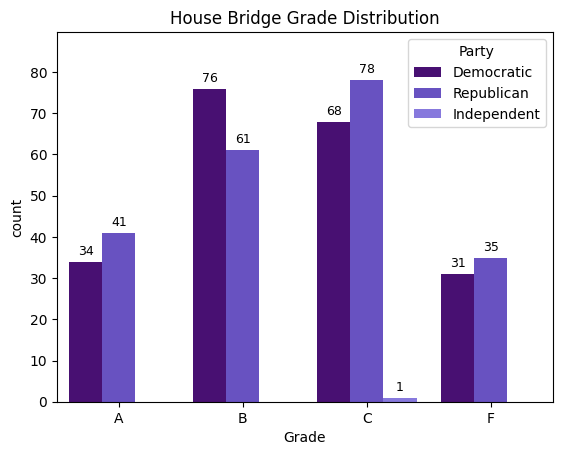

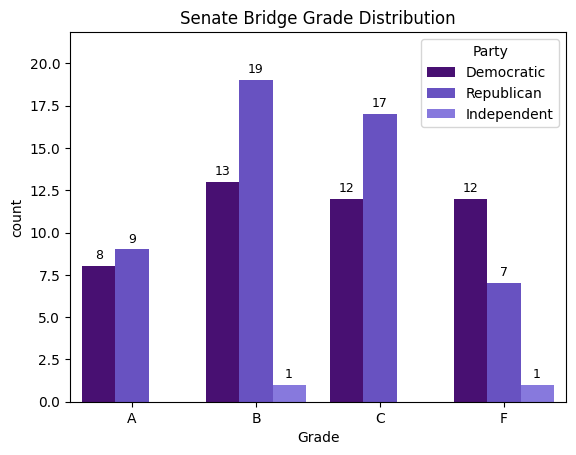

In [51]:
# Create visualizations for grade distributions
order = ["A", "B", "C", "F"]
hue_order = ['Democratic', 'Republican', 'Independent']

purple_palette = ["#4B0082", "#5D3FD3", "#7B68EE"]

def plot_with_counts(data, title):
    ax = sns.countplot(
        x='Grade',
        hue='Party',
        data=data,
        palette=purple_palette,
        order=order,
        hue_order=hue_order
    )
    ax.set_title(title)

    # Calculate maximum height for y-axis scaling
    max_height = max([p.get_height() for p in ax.patches])
    ax.set_ylim(0, max_height * 1.15)  # 15% extra space above

    # Add count labels on bars
    for p in ax.patches:
        height = int(p.get_height())
        if height > 0:
            ax.annotate(
                f'{height}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points'
            )

    plt.show()

# House Grade Distribution
plot_with_counts(house_final_test, "House Bridge Grade Distribution")

# Senate Grade Distribution
plot_with_counts(senate_final_test, "Senate Bridge Grade Distribution")


## **Data Cleanup and Final Output Preparation**

This section prepares the final datasets for export by cleaning up column names, creating standardized abbreviations, and organizing the data structure for maximum usability.

### **Party Abbreviations**
Convert full party names to standard abbreviations for consistency.

### **State and District Formatting**
Create standardized state abbreviations and district formatting for both House and Senate members.

### **Column Reorganization**
Reorganize columns in a logical order for final output, including all source data, normalized scores, and final results.


In [52]:
# Create party abbreviations
house_final_test["Party_Abbr"] = house_final_test["Party"].replace({
    "Republican": "R",
    "Democratic": "D",
    "Independent": "I"
})

senate_final_test["Party_Abbr"] = senate_final_test["Party"].replace({
    "Republican": "R",
    "Democratic": "D",
    "Independent": "I"
})

print("Party abbreviations created successfully.")


Party abbreviations created successfully.


In [53]:
# Create state abbreviations mapping
state_abbr = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS', 'Missouri': 'MO',
    'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ',
    'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH',
    'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT',
    'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY',
    'District of Columbia': 'DC'
}

# Apply state abbreviations
house_final_test['State_Abbr'] = house_final_test['State'].str.strip().map(state_abbr)
senate_final_test['State_Abbr'] = senate_final_test['State'].str.strip().map(state_abbr)

print("State abbreviations created successfully.")


State abbreviations created successfully.


In [54]:
# Create district formatting functions
def make_sd(df, state_col, dist_col):
    """Create State-District format (e.g., 'CA-01')"""
    # Convert district strings to numeric, default 1 for non-numeric (at-large)
    dist_num = pd.to_numeric(df[dist_col], errors='coerce').fillna(1).replace(0, 1).astype(int)
    # Zero-pad to two digits
    dist_str = dist_num.apply(lambda d: f"{d:02d}")
    return df[state_col].astype(str) + '-' + dist_str

def make_sd_DW(df, state_col, dist_col):
    """Create StateDistrict format (e.g., 'CA01')"""
    # Convert district strings to numeric, default 1 for non-numeric (at-large)
    dist_num = pd.to_numeric(df[dist_col], errors='coerce').fillna(1).replace(0, 1).astype(int)
    # Zero-pad to two digits
    dist_str = dist_num.apply(lambda d: f"{d:02d}")
    return df[state_col].astype(str) + dist_str

# Apply district formatting to House
house_final_test['District_Abbr'] = make_sd(house_final_test, 'State_Abbr', 'District')
house_final_test['Dist_DW'] = make_sd_DW(house_final_test, 'State_Abbr', 'District')

# Handle at-large states
at_large_states = ['AK', 'DE', 'ND', 'SD', 'VT', 'WY']
house_final_test.loc[house_final_test['State_Abbr'].isin(at_large_states), 'District_Abbr'] = \
    house_final_test['State_Abbr'] + '-AL'
house_final_test.loc[house_final_test['State_Abbr'].isin(at_large_states), 'Dist_DW'] = \
    house_final_test['State_Abbr'] + '00'

# Senate doesn't have districts
senate_final_test['District_Abbr'] = np.nan
senate_final_test['Dist_DW'] = np.nan

print("District formatting completed successfully.")


District formatting completed successfully.


In [55]:
# Reorganize columns in logical order
column_order = [
    'bioguide_id', 'Name', 'first_name', 'middle_name', 'last_name', 'nickname',
    'Chamber', 'State', 'State_Abbr', 'District', 'District_Abbr', 'Dist_DW',
    'Party', 'Party_Abbr', 'start_year',
    'A: num_bills_with_cross_party_cosponsors', 'A_norm', 'A_weight',
    'B: num_cross_party_cosponsored_bills', 'B_norm', 'B_weight',
    'C: outcome_bipartisanship', 'C_norm', 'C_weight',
    'D: outcome_bipartisanship_pct', 'D_norm', 'D_weight',
    'E: attack_personal', 'E_norm', 'E_weight',
    'F: attack_personal_pct', 'F_norm', 'F_weight',
    'M: Cook PVI Raw', 'M_Cook_PVI_Cap', 'N: nominate_dim1', 'N_ideology_dist', 'P_flag',
    'score_T', 'bonus_m', 'bonus_n', 'bonus_p', 'score_U', 'norm_U', 'Grade'
]

# Reorganize House data
house_final_test = house_final_test[column_order]

# Reorganize Senate data
senate_final_test = senate_final_test[column_order]

print("Column reorganization completed successfully.")


Column reorganization completed successfully.


In [56]:
# Rename columns to final standardized names
house_final_test.rename(columns={
    'score_T': 'T_score',
    'bonus_m': 'M_bonus',
    'bonus_n': 'N_bonus',
    'bonus_p': 'P_bonus',
    'score_U': 'U_score',
    'norm_U': 'Bridge_Score',
    'Grade': 'Bridge_Grade',
    'District_Abbr': 'Dist_abbr'
}, inplace=True)

senate_final_test.rename(columns={
    'score_T': 'T_score',
    'bonus_m': 'M_bonus',
    'bonus_n': 'N_bonus',
    'bonus_p': 'P_bonus',
    'score_U': 'U_score',
    'norm_U': 'Bridge_Score',
    'Grade': 'Bridge_Grade',
    'District_Abbr': 'Dist_abbr'
}, inplace=True)

print("Column renaming completed successfully.")


Column renaming completed successfully.


## **Export to Excel Files**

This section exports the final datasets to Excel files in multiple formats for maximum flexibility and usability.

### **Export Options**
1. **Separate Files:** Individual Excel files for House and Senate
2. **Combined with Separate Sheets:** Single Excel file with separate sheets for House and Senate
3. **Combined Single Sheet:** Single Excel file with all data in one sheet

All files include timestamps in the filename for version control.


In [57]:
house_final[house_final['bioguide_id']=='M001246']

,bioguide_id,Name,first_name,middle_name,last_name,nickname,Chamber,State,District,Party,...,E_norm,E_weight,F: attack_personal_pct,F_norm,F_weight,M: Cook PVI Raw,M_Cook_PVI_Cap,N: nominate_dim1,N_ideology_dist,P_flag


In [58]:
from datetime import datetime

# Generate timestamp for file naming
timestamp = datetime.now().strftime("%Y-%m-%d")

# Export 1: Separate Excel files for House and Senate
house_final_test.to_excel(f'house_scores_119_{timestamp}.xlsx', sheet_name='119 Grades', index=False)
senate_final_test.to_excel(f'senate_scores_119_{timestamp}.xlsx', sheet_name='119 Grades', index=False)

print(f"✓ Separate files exported:")
print(f"  - house_scores_119_{timestamp}.xlsx")
print(f"  - senate_scores_119_{timestamp}.xlsx")

✓ Separate files exported:
  - house_scores_119_2026-06-02.xlsx
  - senate_scores_119_2026-06-02.xlsx


In [59]:
# Export 2: Combined file with separate sheets
with pd.ExcelWriter(f'congress_scores_119_separate_sheets_{timestamp}.xlsx') as writer:
    house_final_test.to_excel(writer, sheet_name='House', index=False)
    senate_final_test.to_excel(writer, sheet_name='Senate', index=False)

print(f"✓ Combined file with separate sheets exported:")
print(f"  - congress_scores_119_separate_sheets_{timestamp}.xlsx")


✓ Combined file with separate sheets exported:
  - congress_scores_119_separate_sheets_2026-06-02.xlsx


In [60]:
# Export 3: Combined file with single sheet
congress_combined = pd.concat([house_final_test, senate_final_test])
congress_combined.to_excel(f'congress_scores_119_single_sheet_{timestamp}.xlsx', sheet_name='119 Grades', index=False)

print(f"✓ Combined file with single sheet exported:")
print(f"  - congress_scores_119_single_sheet_{timestamp}.xlsx")


✓ Combined file with single sheet exported:
  - congress_scores_119_single_sheet_2026-06-02.xlsx
